# Making the boxplots
This notebook generates box-and-whisker plots for each of the 24 subregions in the PNW and CA regions

In [1]:
import xarray as xa
import matplotlib.pyplot as plt
from matplotlib import cbook
import numpy as np
import sys
sys.path.append("..")
import fmap as fm
import regionmask
import cftime
import geopandas as gpd
import pandas as pd
from glob import glob
from matplotlib import table
import pickle

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/home/tcorrie/.conda/envs/rmask/share/proj failed


In [2]:
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 25)

In [3]:
wus_db = gpd.read_file('../watersheds_WUS.geojson', driver='GeoJSON')[['huc4', 'name', 'geometry']]

In [4]:
# This should have been calculated in 3_Precipitation/intermediate_precip_processing.ipynb
prec_ARday_all = pickle.load(open('/glade/work/tcorrie/ARdata/pmean/prec_mean_all.pkl', 'rb'))

In [5]:
# filer_colors controls some of the details in the box and whisker plots so everything is consistent.
def flier_colors(bp, color, pos):

    for box in bp['boxes'][pos:pos+1:]:
        box.set(color = color)
        
    for patch in bp['boxes']:
        patch.set_facecolor('white')

    for whisker in bp['whiskers'][pos*2:pos*2+2]:
        whisker.set(color = color)
    
    # changing color and linewidth of
    for cap in bp['caps'][pos*2:pos*2+2]:
        cap.set(color = color)

    for median in bp['medians'][pos:pos+1:]:
        median.set(color = color)

# get_filer_data returns any data above the 97.5th percentile of the data passed in
def get_flier_data(data):
    bstat = cbook.boxplot_stats(data, whis=(2.5, 97.5))#[0]['fliers']
    bdata = bstat[0]['fliers'][np.where(bstat[0]['fliers'] > bstat[0]['whishi'])]
    return bdata

# box_mean returns the mean of the data passed in
def box_mean(data):
    return cbook.boxplot_stats(data)[0]['mean']


/glade/derecho/scratch/tcorrie/tmp/ipykernel_81527/2192334476.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  f1, (a1, a2) = plt.subplots(2, 1, figsize=(14,8), sharex=True, gridspec_kw = {'hspace': 0.1})


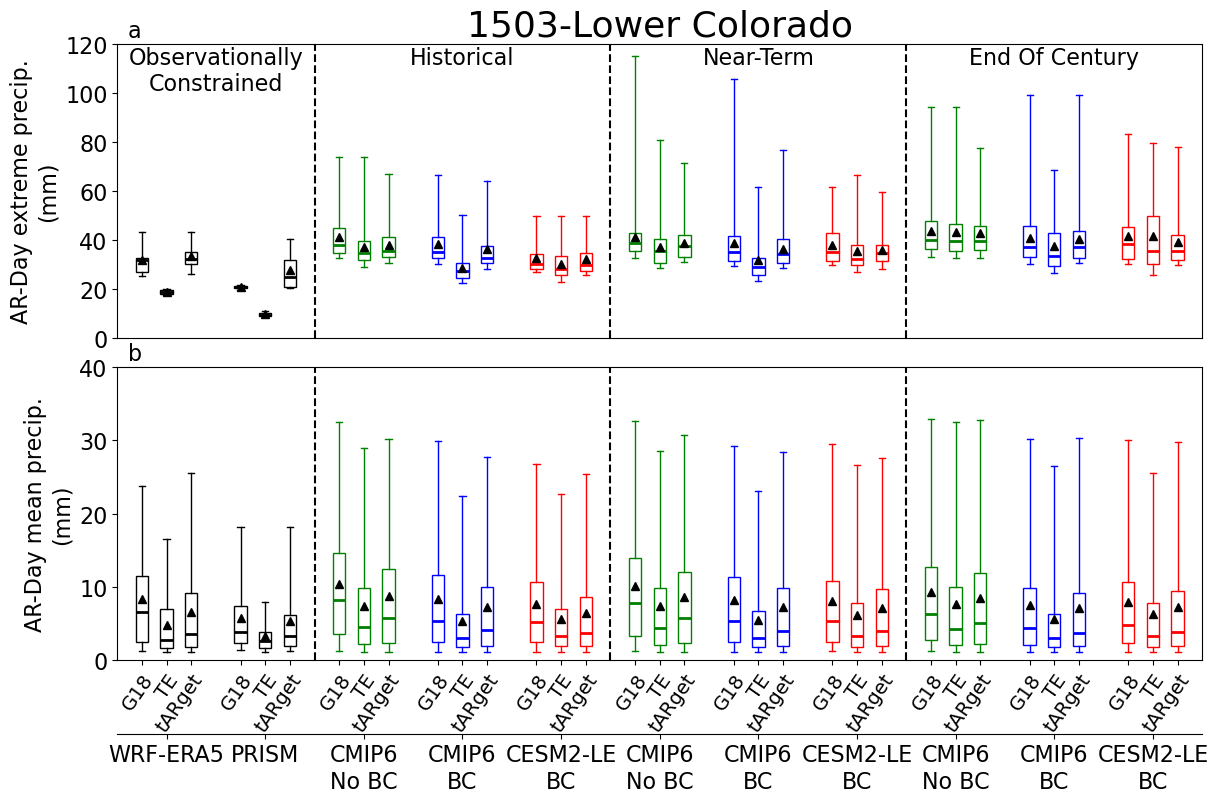

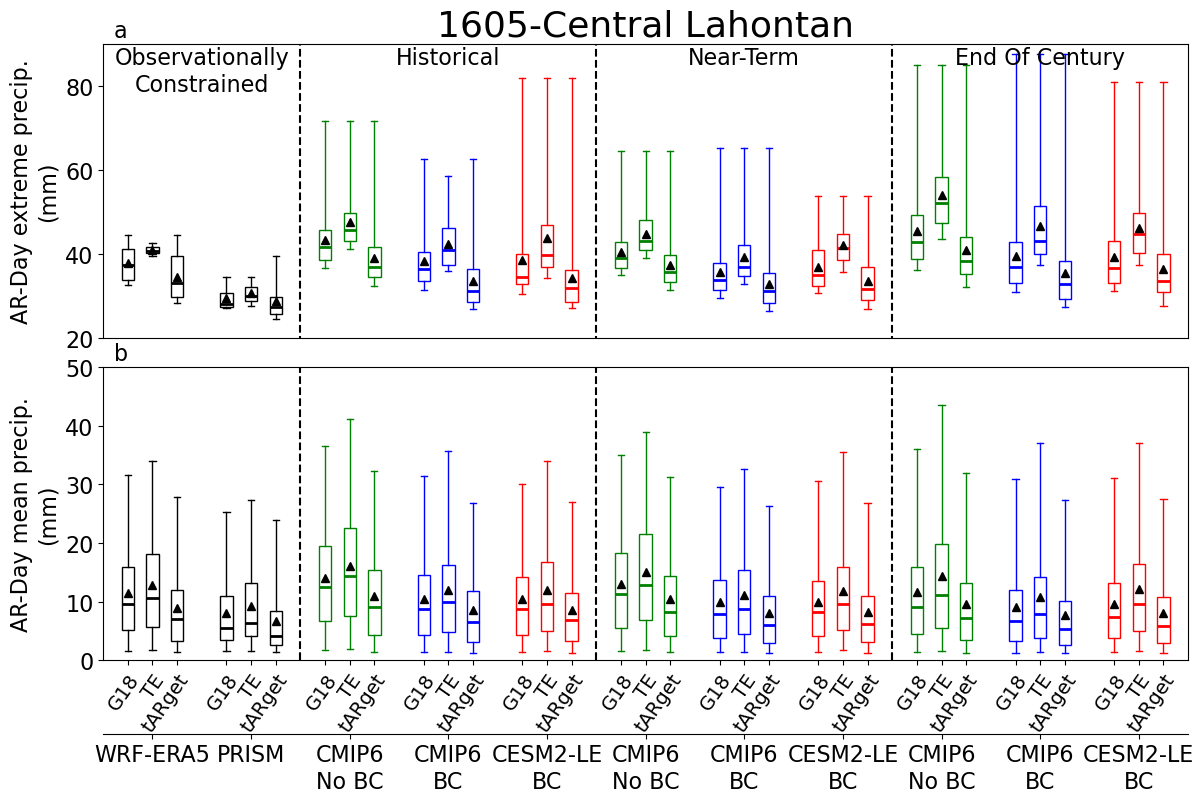

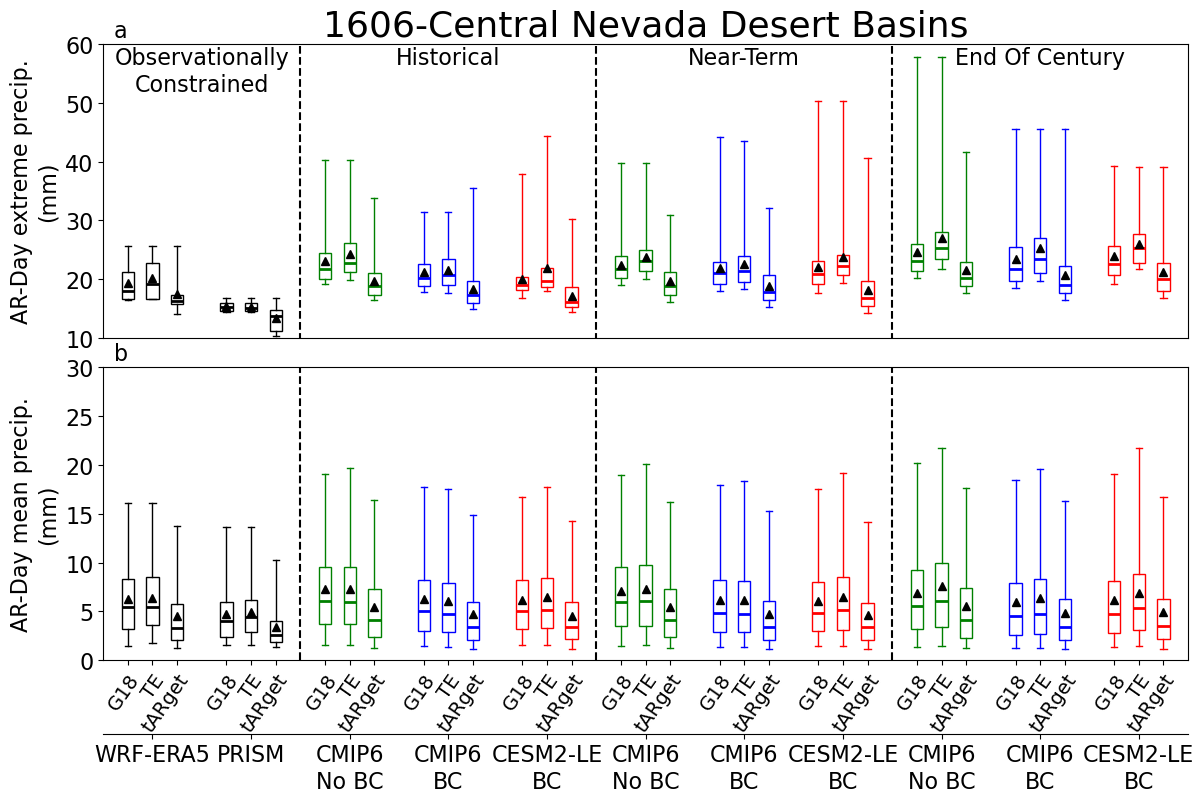

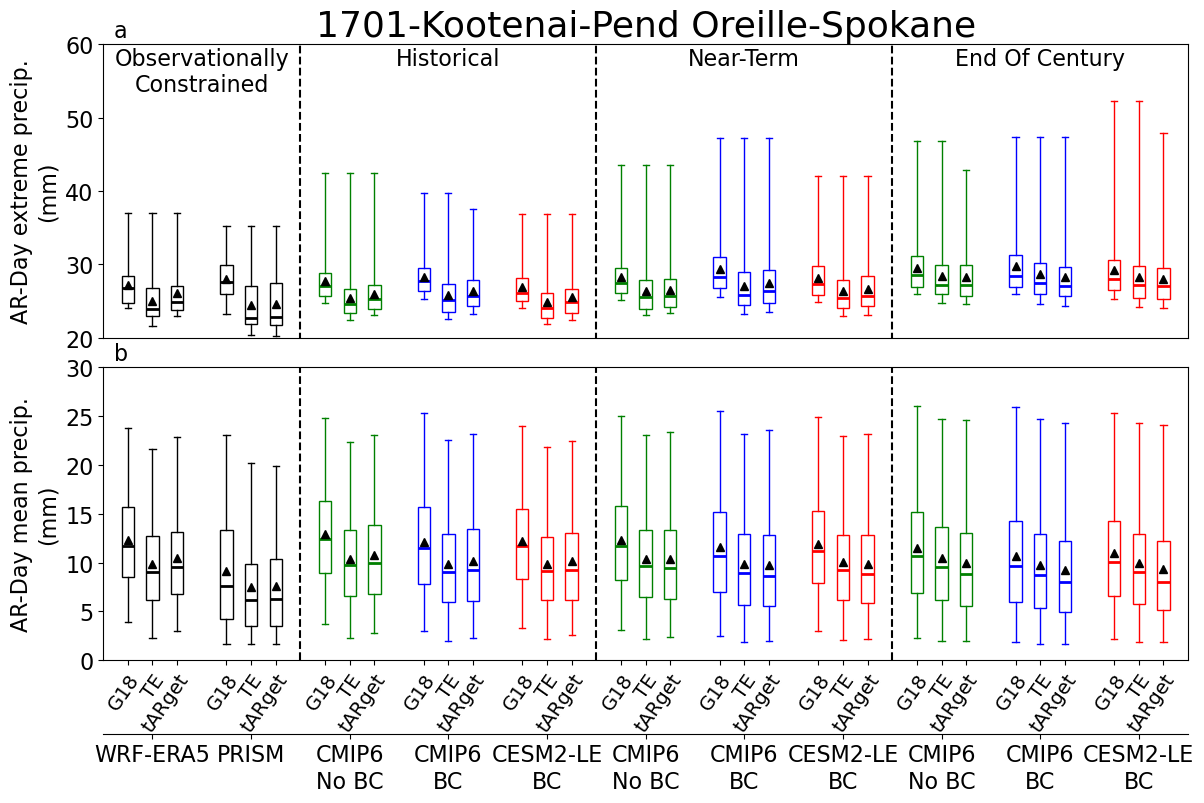

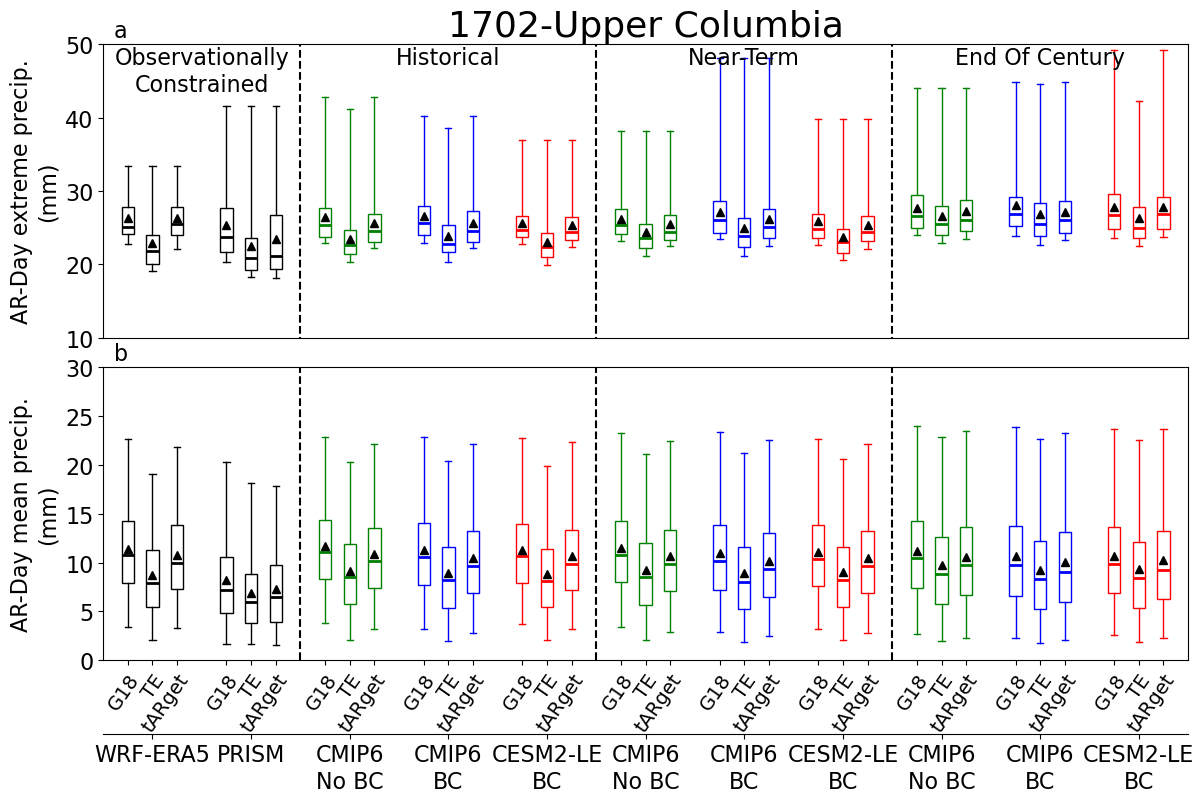

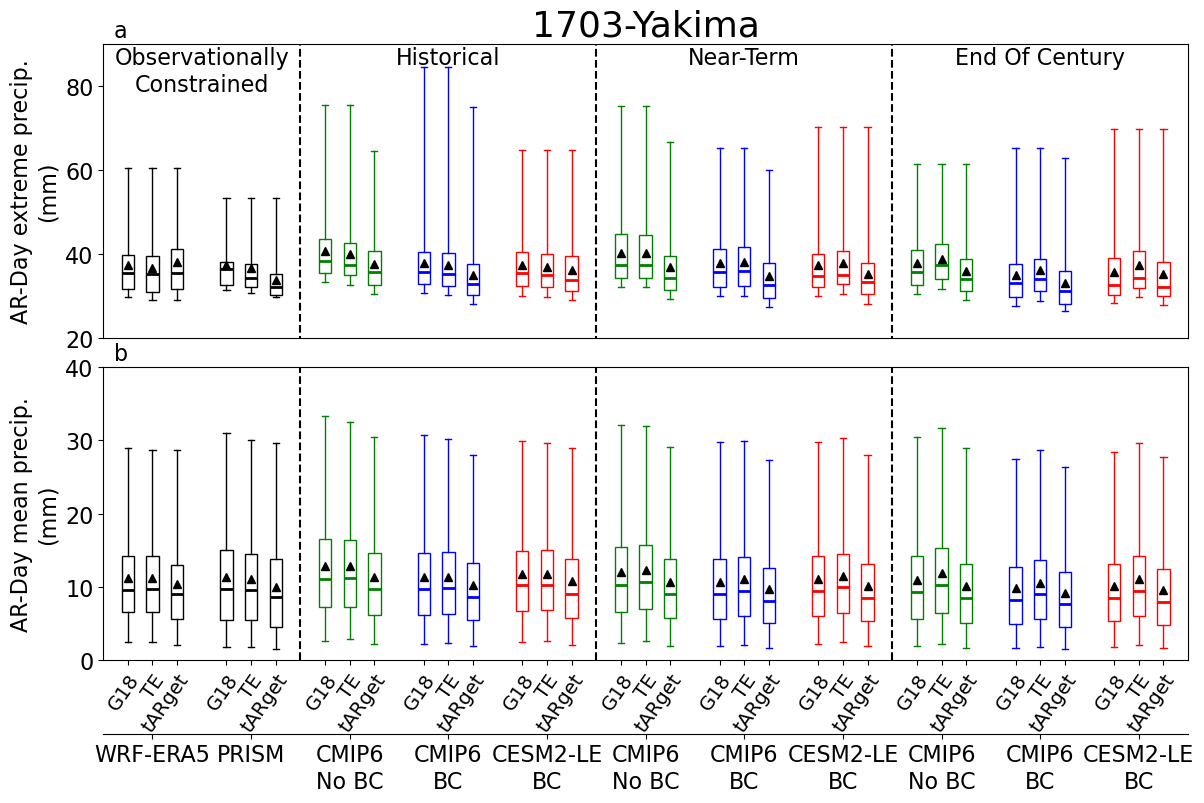

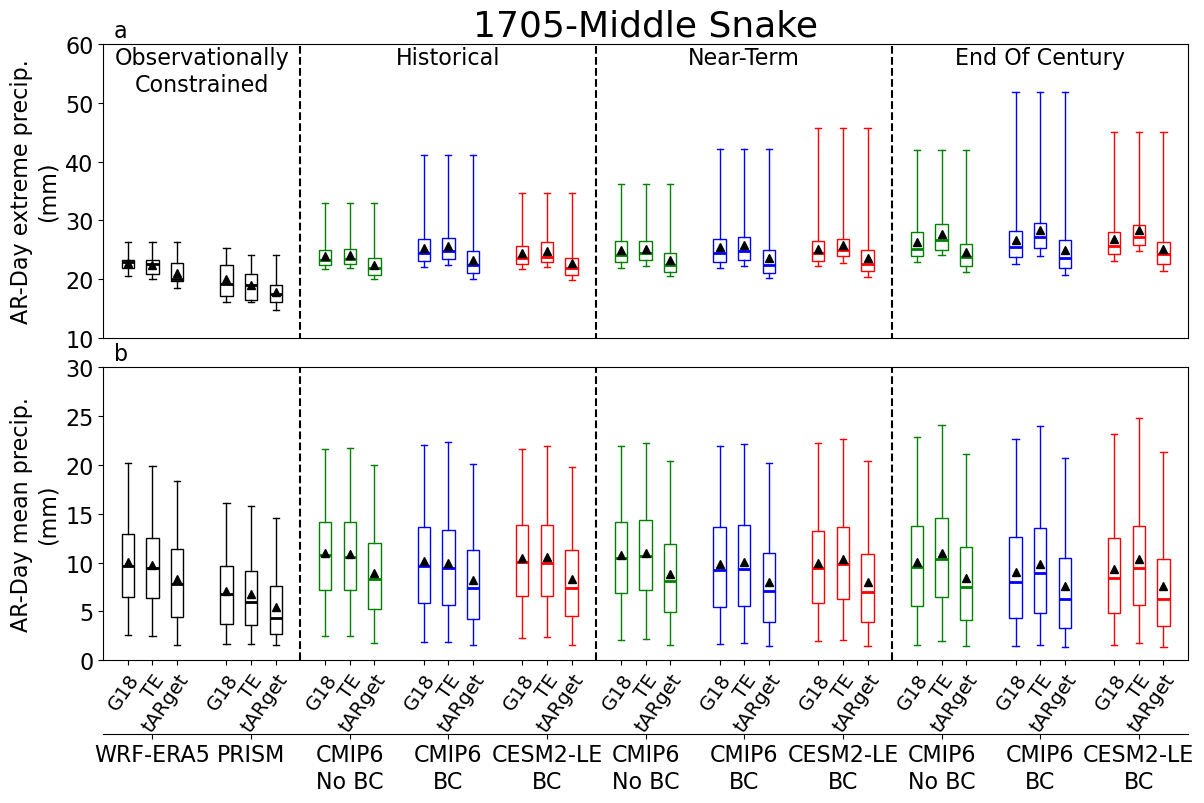

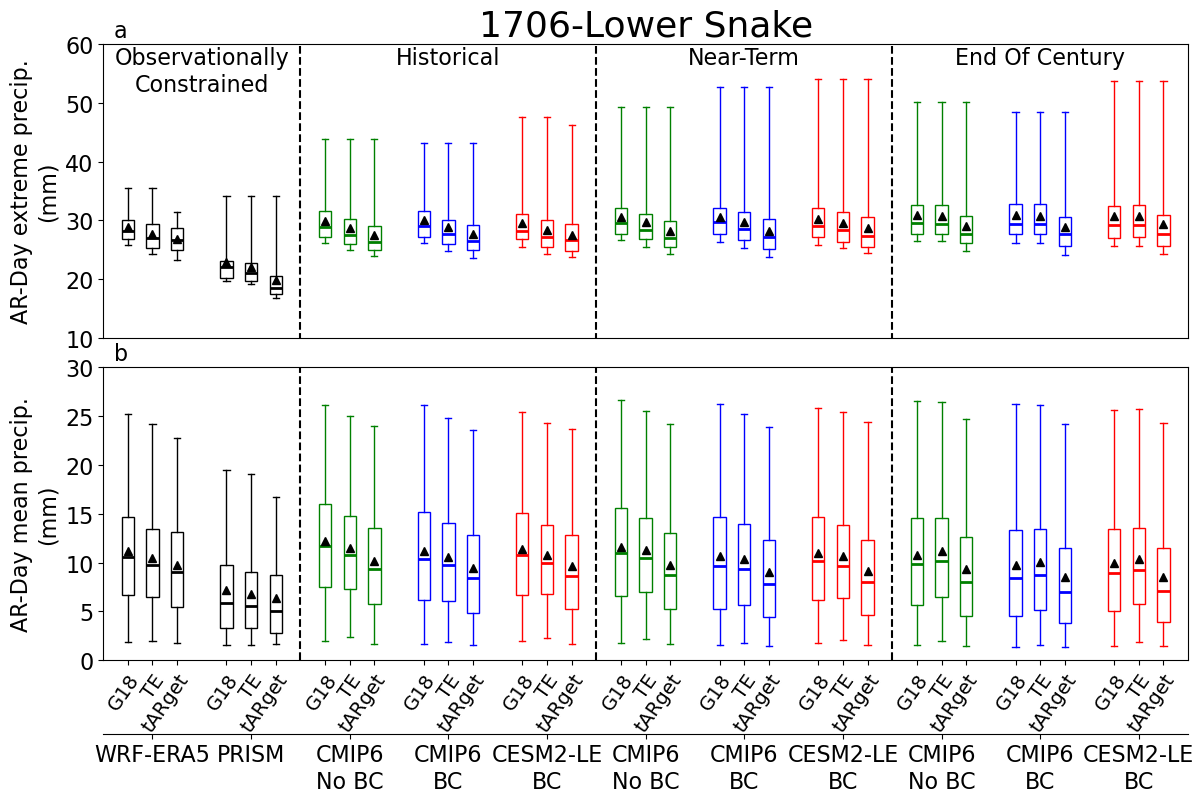

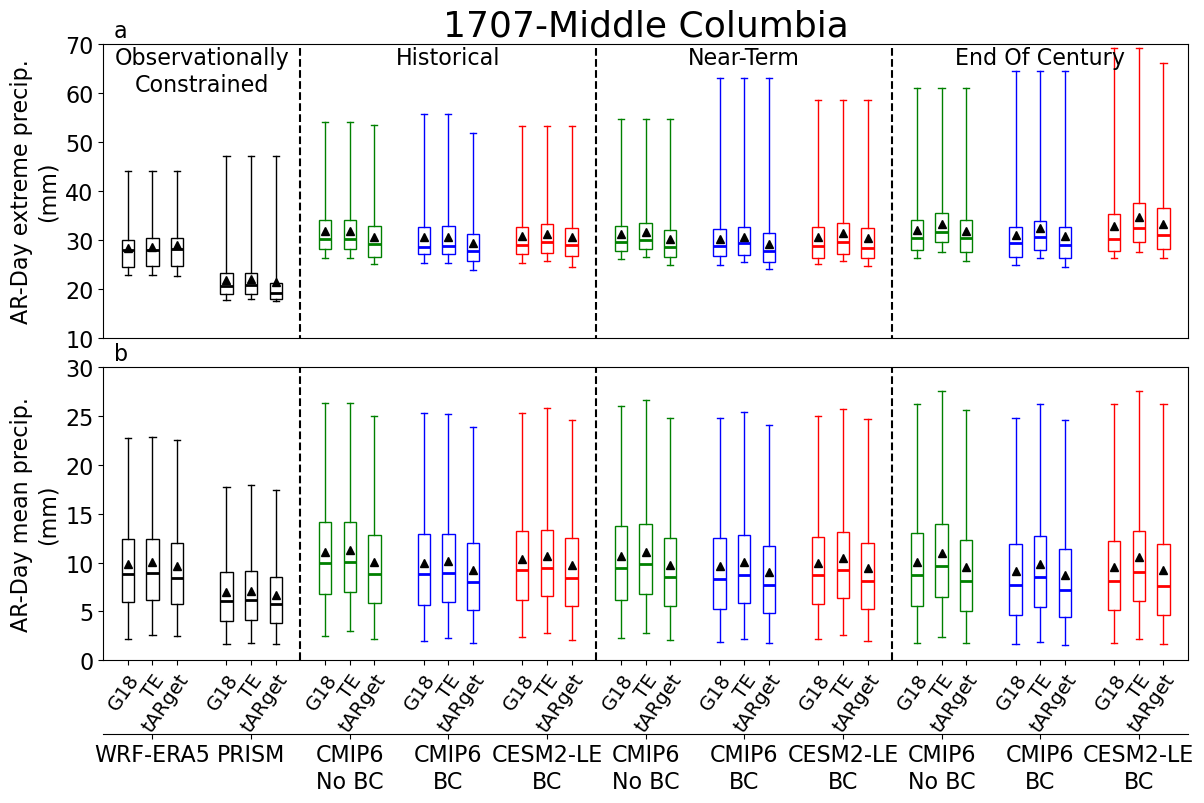

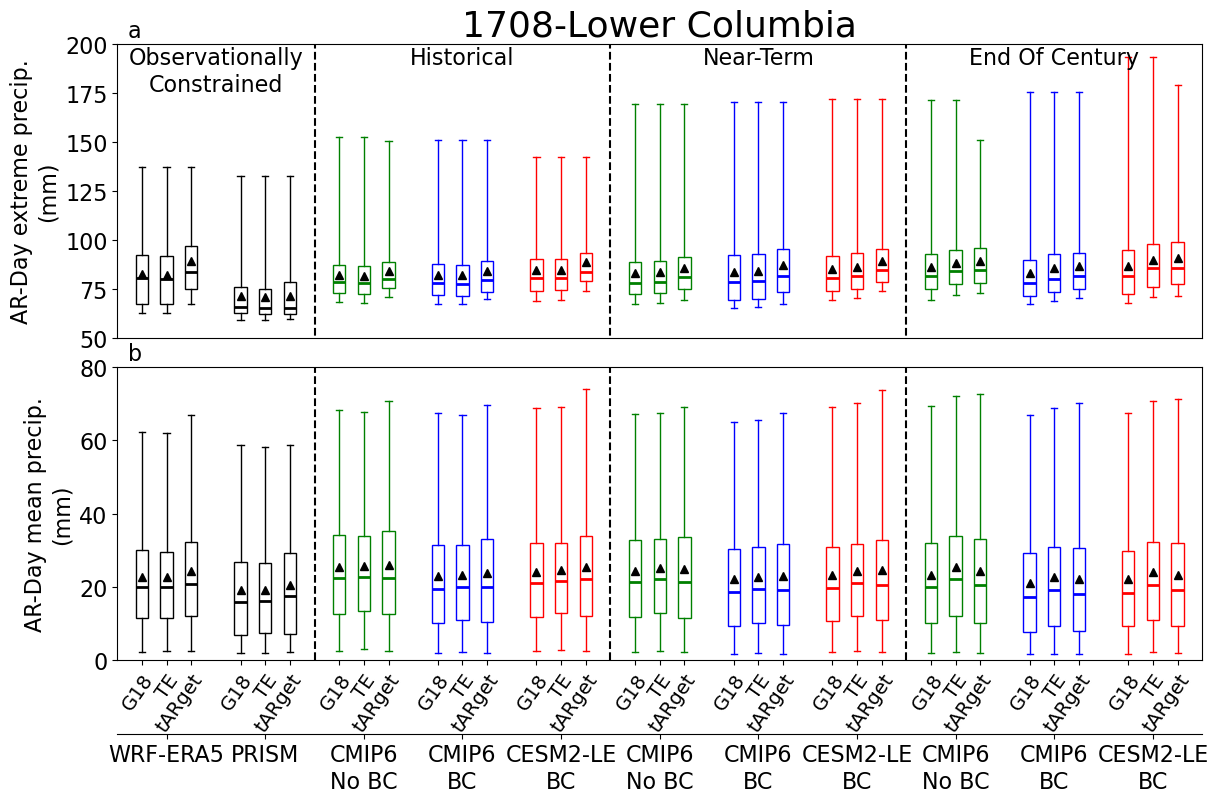

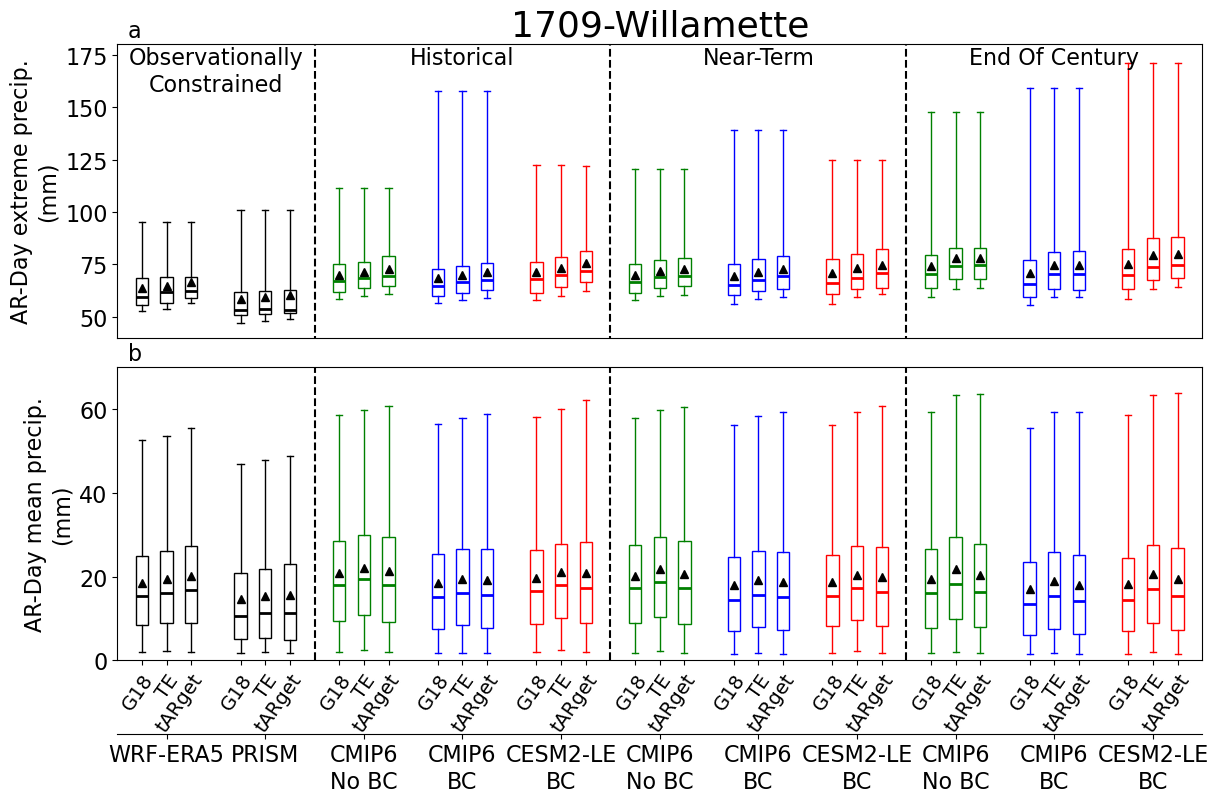

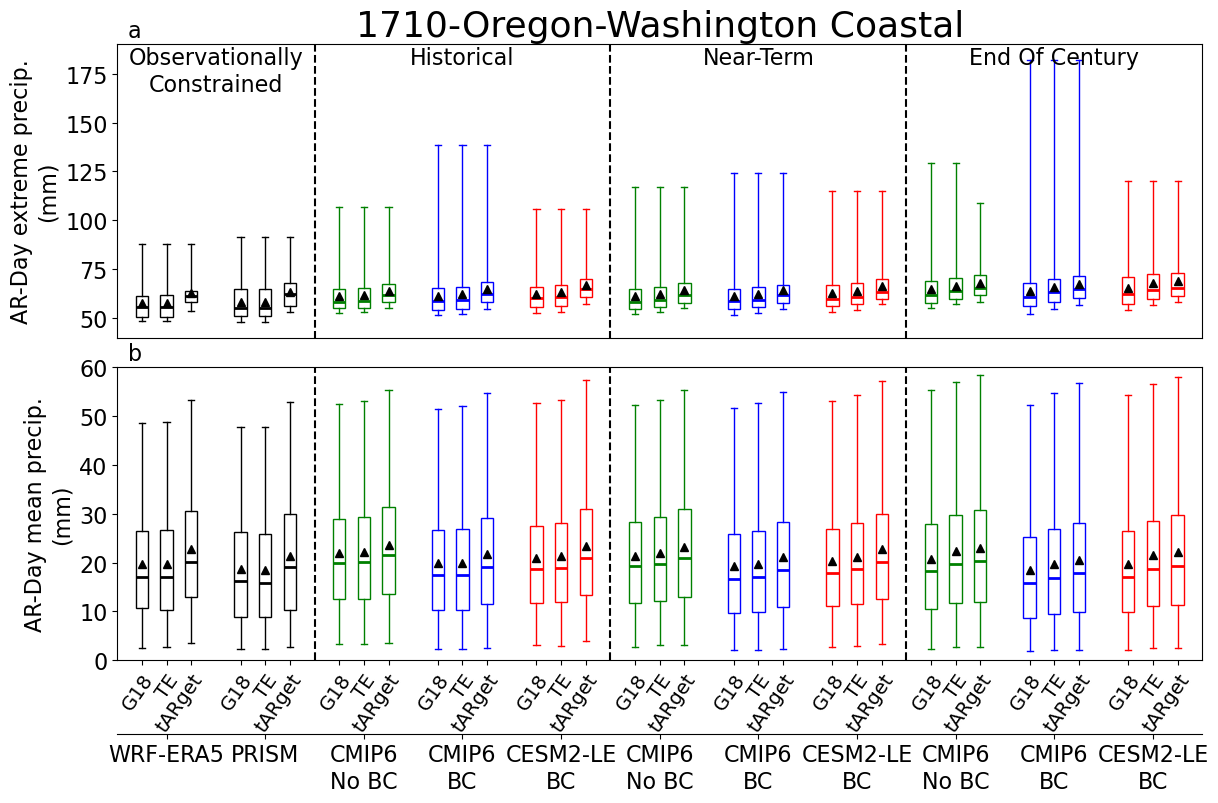

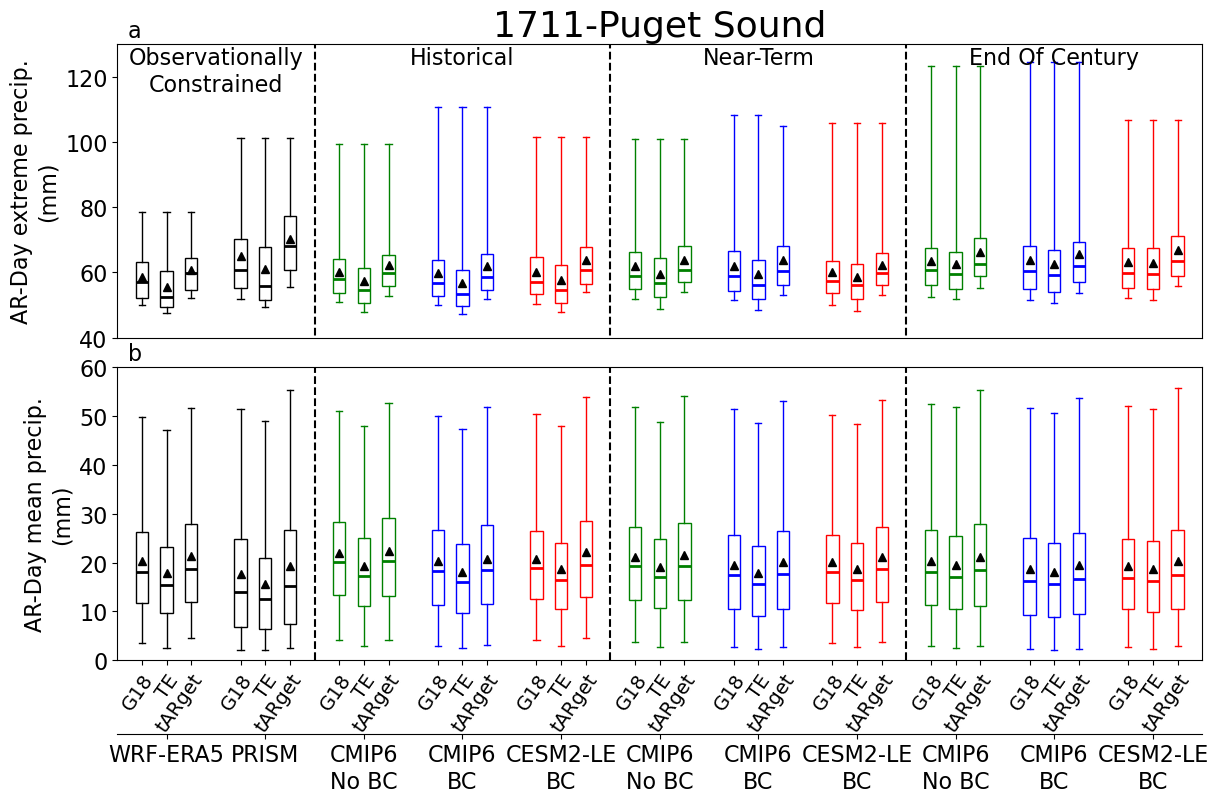

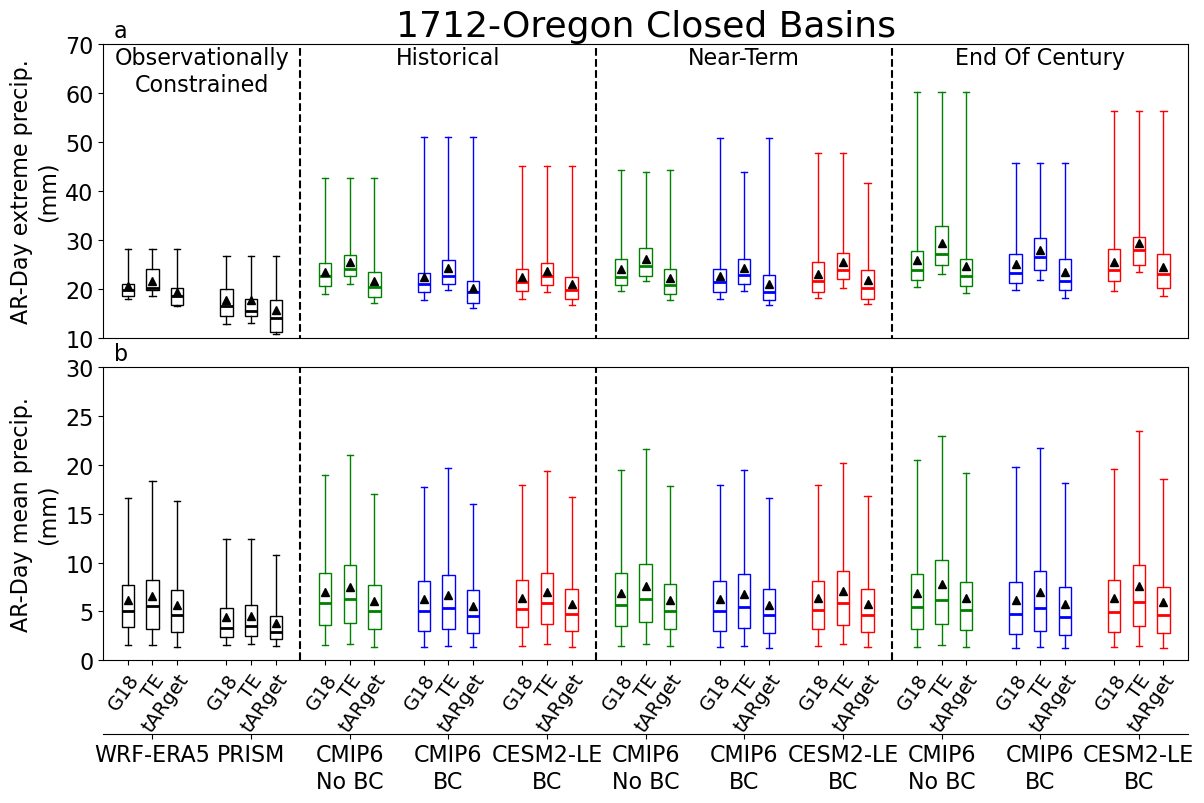

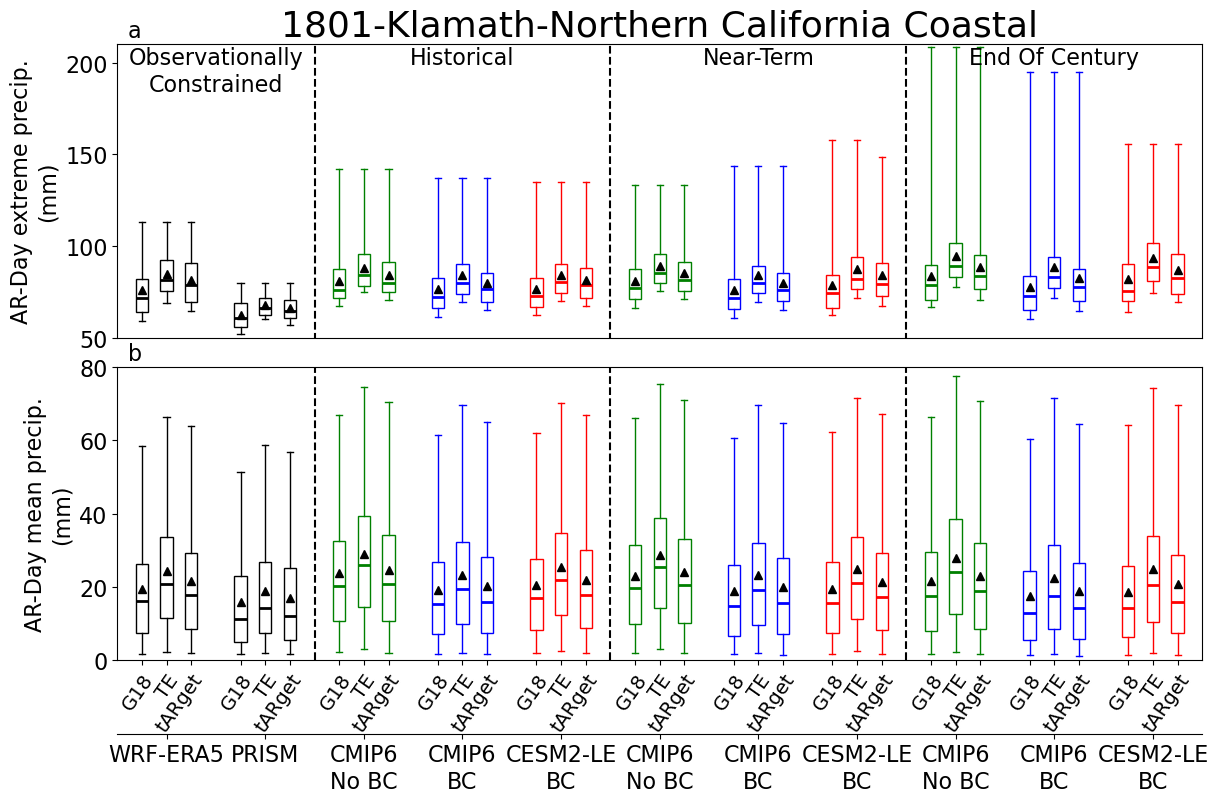

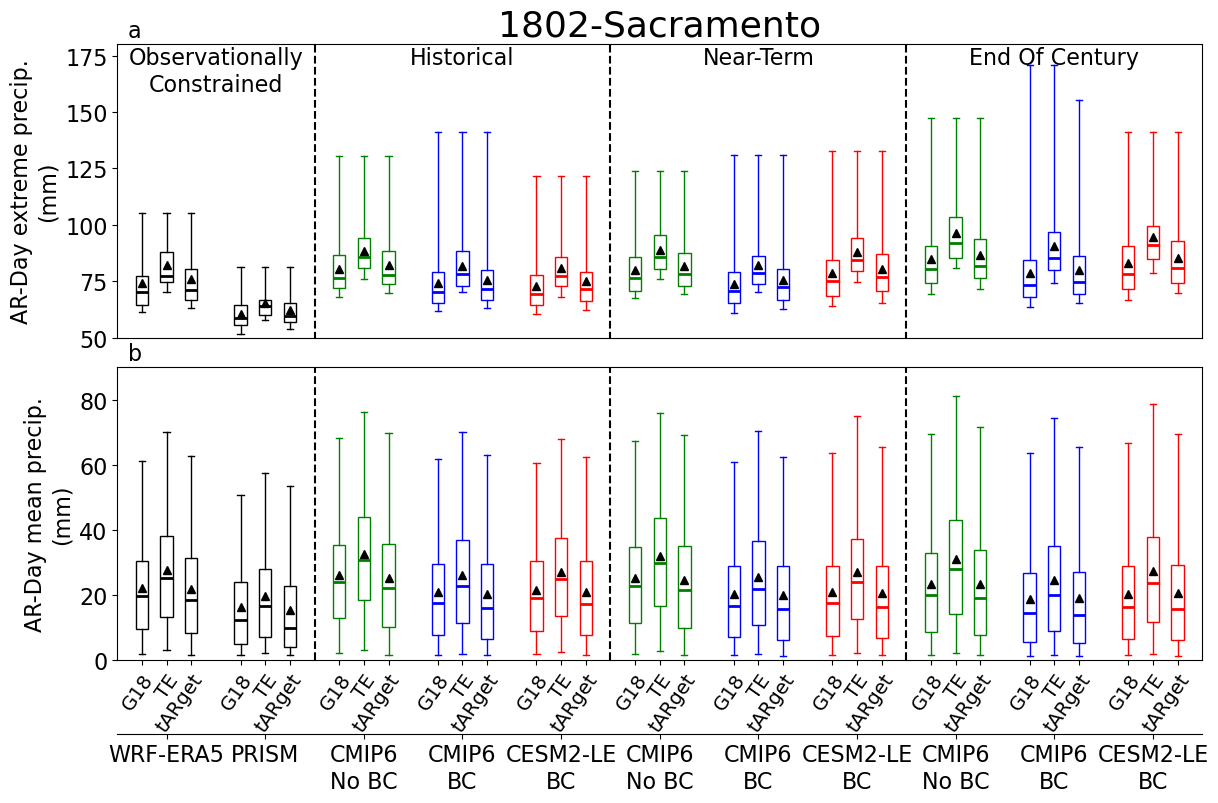

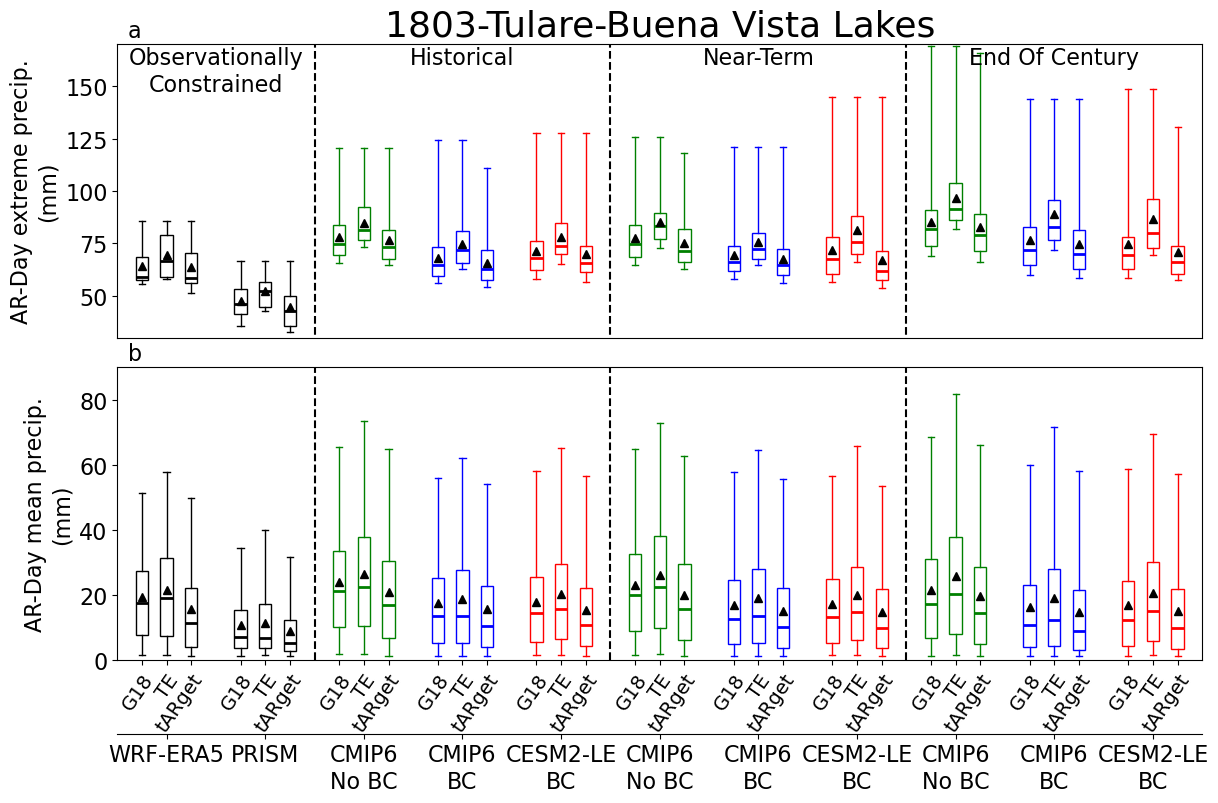

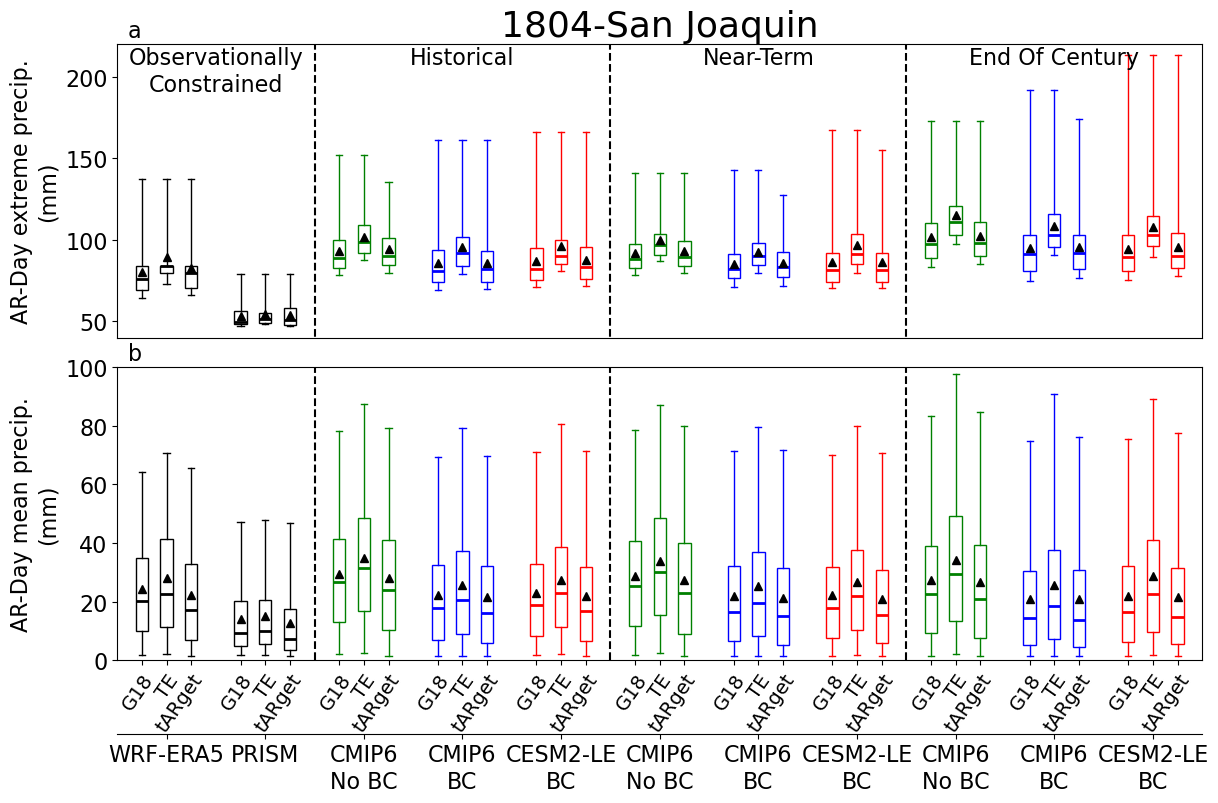

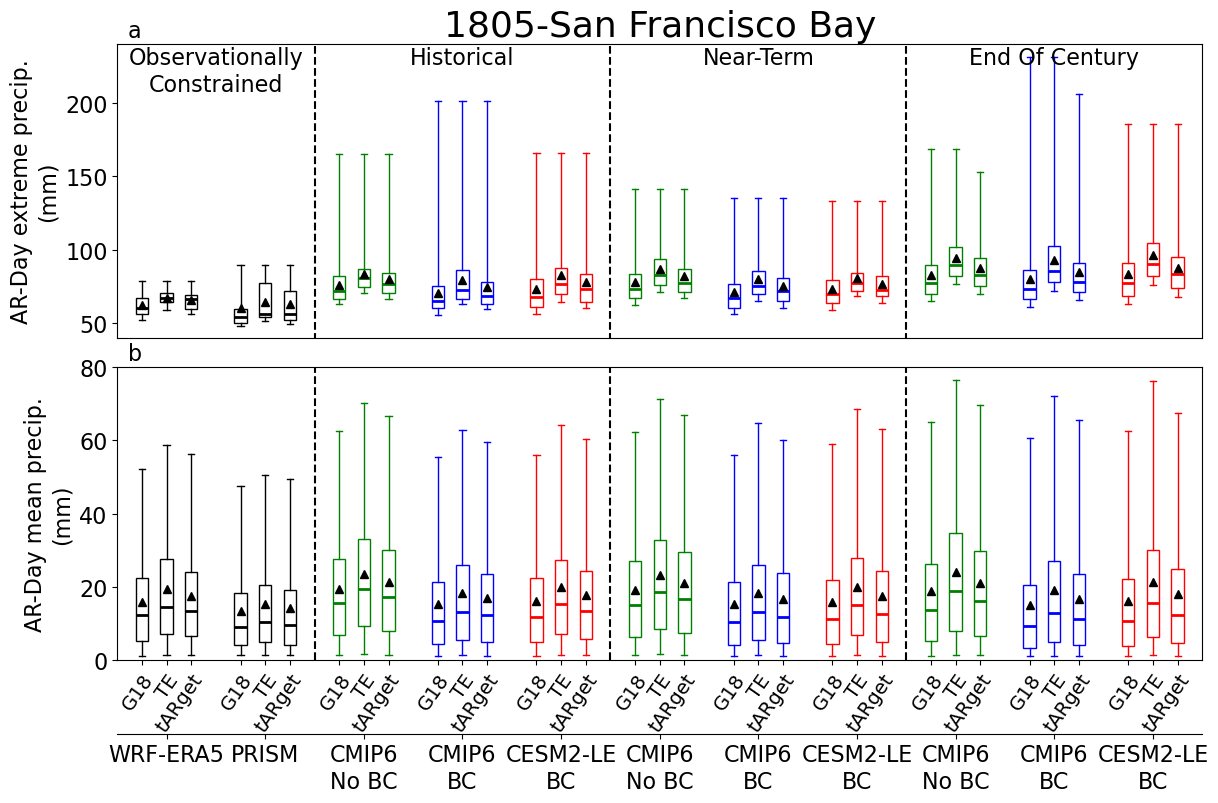

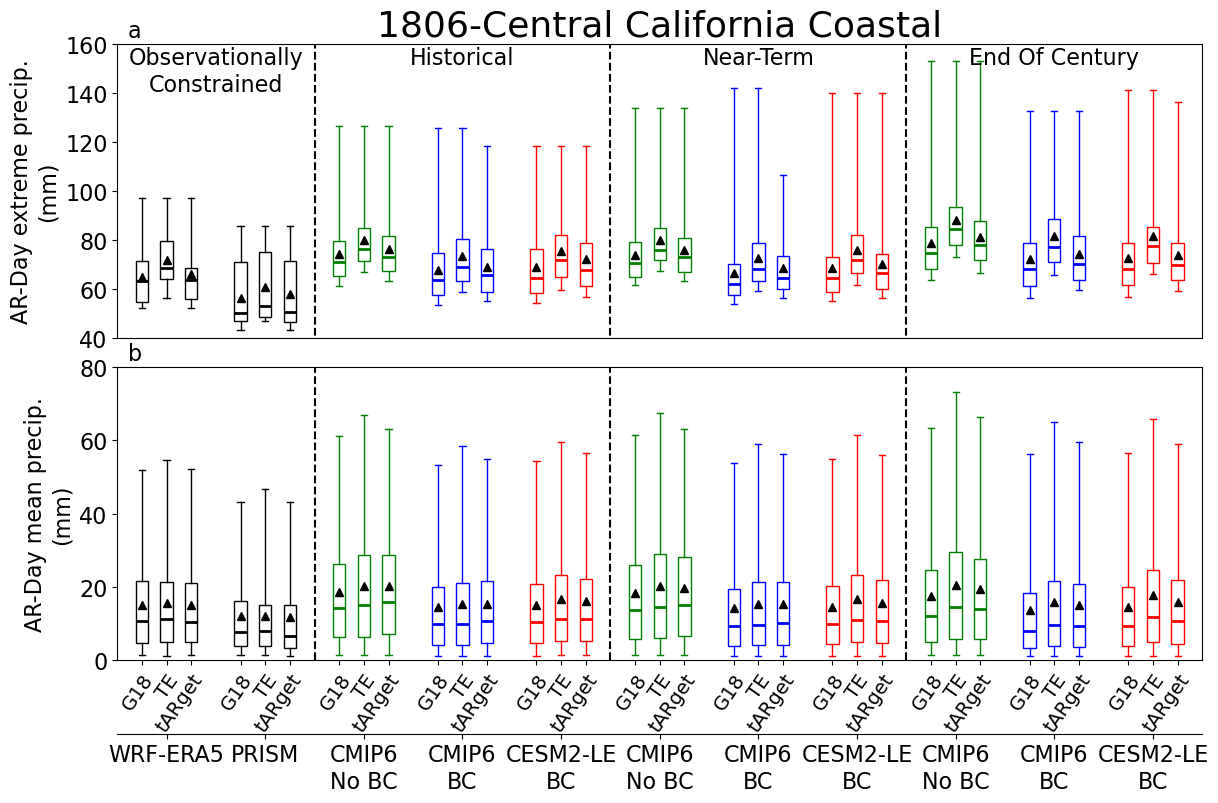

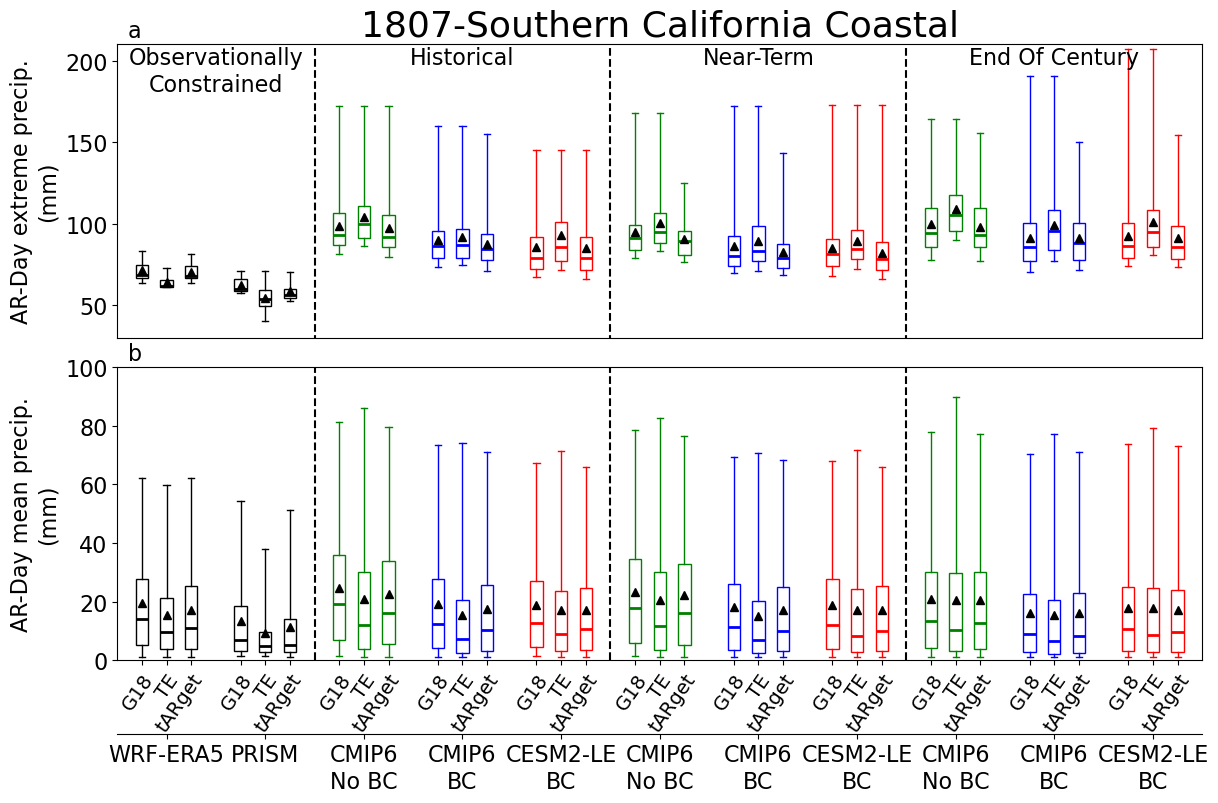

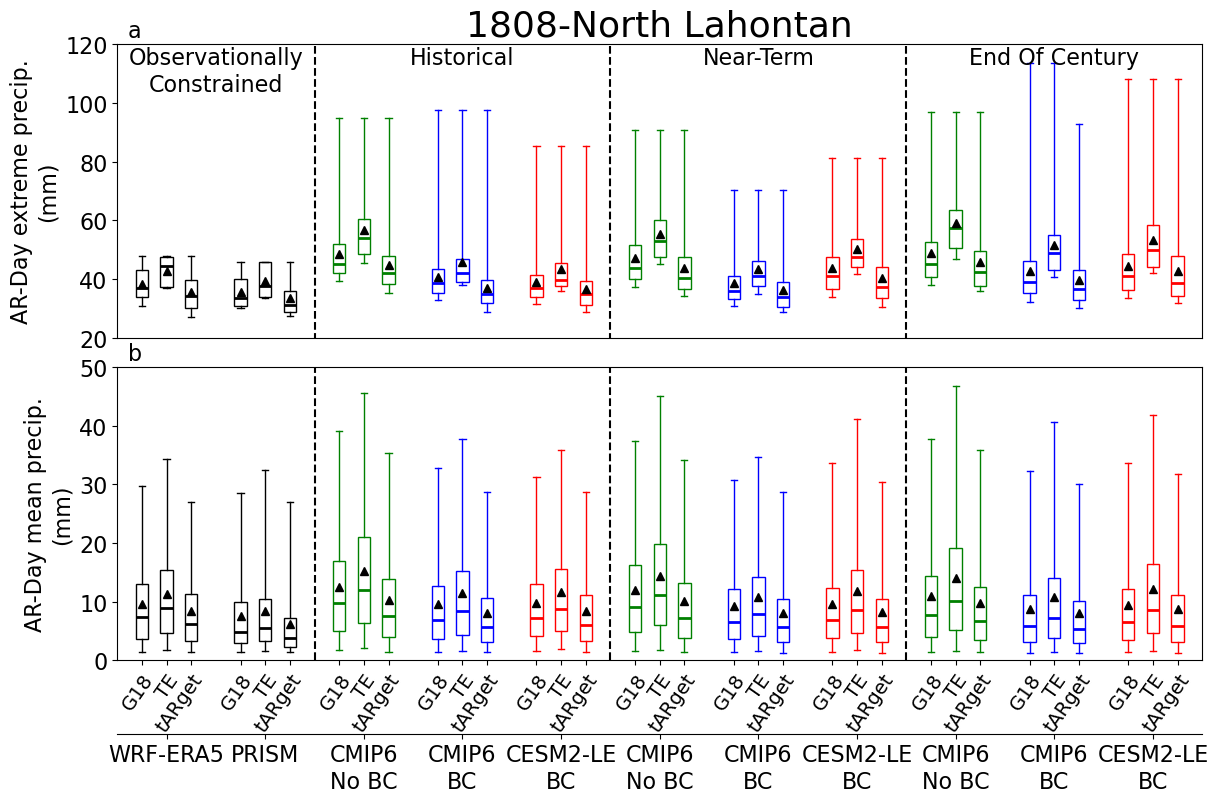

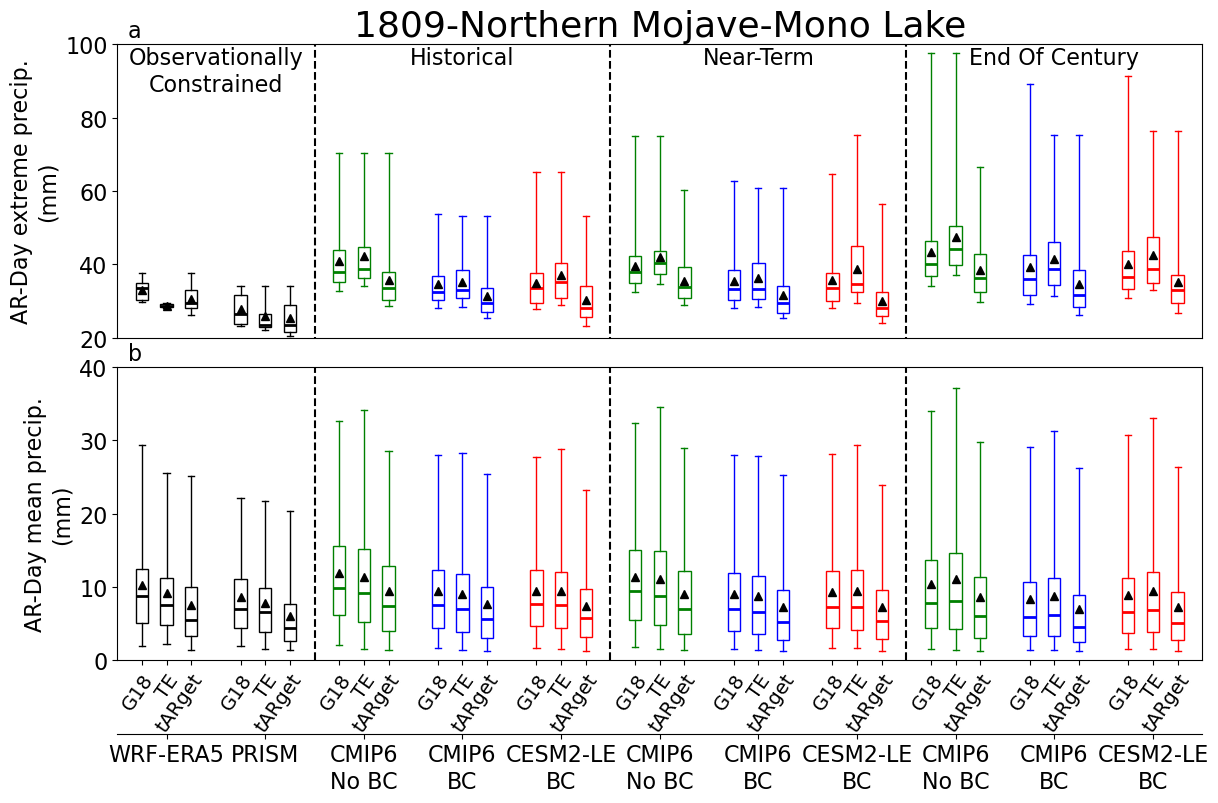

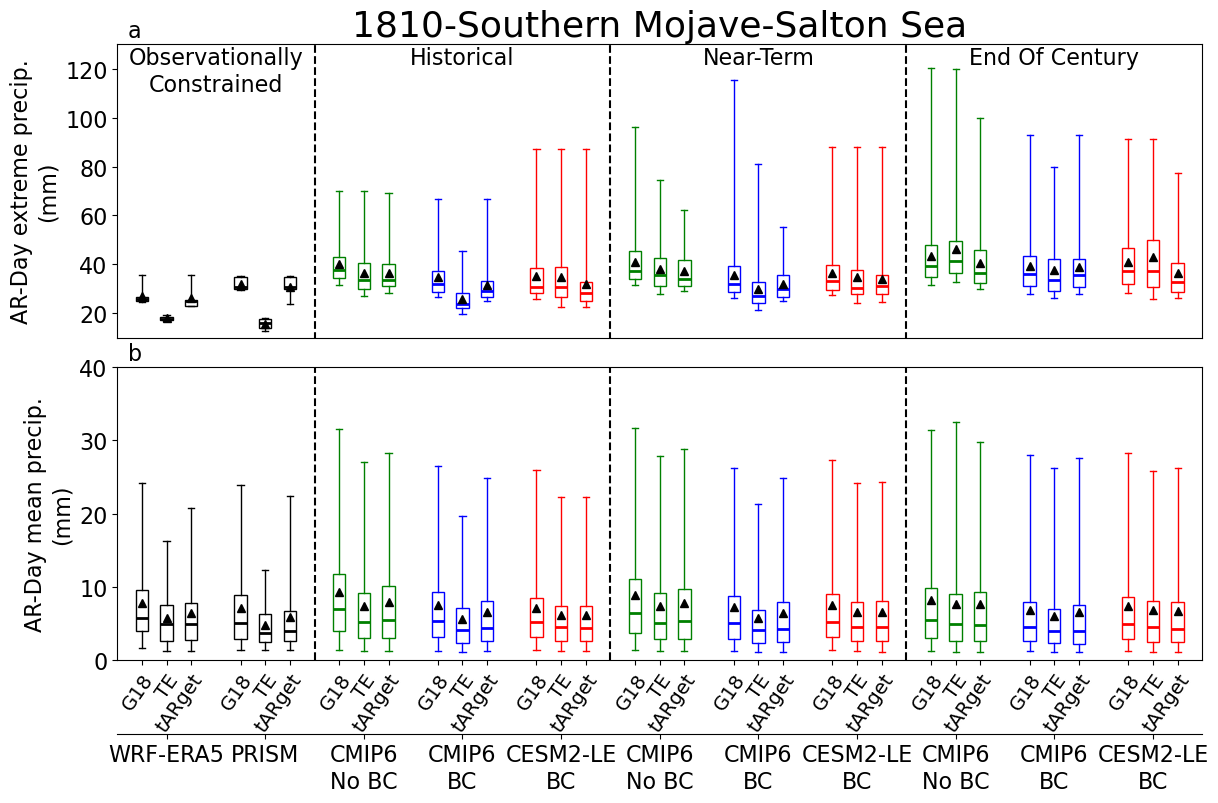

In [8]:
for idx, row in wus_db.iterrows(): # Loop through each subregion individually.
    id = row.huc4
    name = row['name']
    name_string = name.replace(" ","_")
    prec_ARday_ws = prec_ARday_all[str(id)]


    all_data = [prec_ARday_ws['wrfera5']['G18']['historical'], prec_ARday_ws['wrfera5']['TE']['historical'], prec_ARday_ws['wrfera5']['tARget']['historical'],
                prec_ARday_ws['prism']['G18']['historical'], prec_ARday_ws['prism']['TE']['historical'], prec_ARday_ws['prism']['tARget']['historical'],
                prec_ARday_ws['cmip6nonbc']['G18']['historical'], prec_ARday_ws['cmip6nonbc']['TE']['historical'], prec_ARday_ws['cmip6nonbc']['tARget']['historical'],
                prec_ARday_ws['cmip6nonbc']['G18']['near-term'], prec_ARday_ws['cmip6nonbc']['TE']['near-term'], prec_ARday_ws['cmip6nonbc']['tARget']['near-term'],
                prec_ARday_ws['cmip6nonbc']['G18']['end-of-century'], prec_ARday_ws['cmip6nonbc']['TE']['end-of-century'], prec_ARday_ws['cmip6nonbc']['tARget']['end-of-century'],
                prec_ARday_ws['cmip6bc']['G18']['historical'], prec_ARday_ws['cmip6bc']['TE']['historical'], prec_ARday_ws['cmip6bc']['tARget']['historical'],
                prec_ARday_ws['cmip6bc']['G18']['near-term'], prec_ARday_ws['cmip6bc']['TE']['near-term'], prec_ARday_ws['cmip6bc']['tARget']['near-term'],
                prec_ARday_ws['cmip6bc']['G18']['end-of-century'], prec_ARday_ws['cmip6bc']['TE']['end-of-century'], prec_ARday_ws['cmip6bc']['tARget']['end-of-century'],
                prec_ARday_ws['cesm2le']['G18']['historical'], prec_ARday_ws['cesm2le']['TE']['historical'], prec_ARday_ws['cesm2le']['tARget']['historical'],
                prec_ARday_ws['cesm2le']['G18']['near-term'], prec_ARday_ws['cesm2le']['TE']['near-term'], prec_ARday_ws['cesm2le']['tARget']['near-term'],
                prec_ARday_ws['cesm2le']['G18']['end-of-century'], prec_ARday_ws['cesm2le']['TE']['end-of-century'], prec_ARday_ws['cesm2le']['tARget']['end-of-century'],
               ]
    f1, (a1, a2) = plt.subplots(2, 1, figsize=(14,8), sharex=True, gridspec_kw = {'hspace': 0.1})

    # Find the maximum value of the means, then add a bit for the upper bound plot on the bottom row.
    max_val_black = 0
    for loa in all_data:
        max_val_black = np.maximum(np.percentile(loa, 97.5), max_val_black)
    max_val_black_plot = np.ceil(max_val_black/10)*10

    extremes = [get_flier_data(model) for model in all_data]

    # Find the bounds of the extremes, then pad a bit for the plot to show the entire box-and-whisker plots.
    max_val_red = 0 # These are simply starting values and will be replaced.
    min_val_red = 9999
    for loa in extremes:
        max_val_red = np.maximum(np.max(loa), max_val_red)
        min_val_red = np.minimum(np.min(loa), min_val_red)
    max_val_plot_red = np.ceil(max_val_red / 10) * 10
    min_val_plot_red = np.floor(min_val_red / 10) * 10

    # Dictionary setup to be passed for displaying the means
    meanprops = dict(marker='^', markerfacecolor='black', markeredgecolor='black')
    meanprops_e = dict(marker='^', markerfacecolor='black', markeredgecolor='black')

    positions = [0.1,0.2,0.3, 0.5,0.6,0.7,
                 0.9,1.0,1.1, 2.1,2.2,2.3, 3.3,3.4,3.5,
                 1.3,1.4,1.5, 2.5,2.6,2.7, 3.7,3.8,3.9,
                 1.7,1.8,1.9, 2.9,3.0,3.1, 4.1,4.2,4.3
                ]
    
    labels = ["G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
              "G18", "TE", "tARget",
             ]
    outer_labels = ['WRF-ERA5',
                    'PRISM',
                    'CMIP6\nNo BC',
                    'CMIP6\nBC',
                    'CESM2-LE\nBC',
                    'CMIP6\nNo BC',
                    'CMIP6\nBC',
                    'CESM2-LE\nBC',
                    'CMIP6\nNo BC',
                    'CMIP6\nBC',
                    'CESM2-LE\nBC'
                   ]

    # Set up structure of top row
    a1.set_xlim(0, 4.4)
    a1.set_ylim(min_val_plot_red, max_val_plot_red)
    a1.set_ylabel("AR-Day extreme precip.\n(mm)", fontsize=16)
    a1.tick_params(axis='y', labelsize=16)

    # Plotting the extremes (top row)
    fbpt = a1.boxplot(extremes, positions=positions, whis=(0, 100), widths=0.05, labels=labels, showmeans=True, patch_artist=True, medianprops=dict(color='black', linewidth=2), meanprops=meanprops_e)

    # Make ensemble comparison easier to visualize.
    for i in range(6, 33):
        if i < 15:
            flier_colors(fbpt, 'green', i)
        elif i < 24:
            flier_colors(fbpt, 'blue', i)
        else:
            flier_colors(fbpt, 'red', i)

    # Add time period dividers for easier figure reading.
    a1.vlines([0.8, 2.0, 3.2], 0, max_val_plot_red, colors='k', linestyles='dashed')
    a1.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    a1.text((0.7+0.1)/2, max_val_plot_red*0.995, "Observationally\nConstrained", ha='center', va='top', fontsize=16)
    a1.text((1.9+0.9)/2, max_val_plot_red*0.995, "Historical", ha='center', va='top', fontsize=16)
    a1.text((3.1+2.1)/2, max_val_plot_red*0.995, "Near-Term", ha='center', va='top', fontsize=16)
    a1.text((4.3+3.3)/2, max_val_plot_red*0.995, "End Of Century", ha='center', va='top', fontsize=16)
    a1.set_title(f"{id}-{name}", fontsize=26)

    # Set up structure of bottom row
    a2.set_xlim(0, 4.4)
    a2.set_ylim(0, max_val_black_plot)
    a2.set_ylabel("AR-Day mean precip.\n(mm)", fontsize=16)
    a2.tick_params(axis='y', labelsize=16)

    # Plot all data on the bottom row
    bpt = a2.boxplot(all_data, positions=positions, labels=labels, widths=0.05, whis=(2.5, 97.5), showfliers=False, showmeans=True, patch_artist=True, medianprops=dict(color='black', linewidth=2), meanprops=meanprops)
    a2.vlines([0.8, 2.0, 3.2], 0, max_val_black_plot, colors='k', linestyles='dashed')
    a2.set_xticks(positions)
    a2.set_xticklabels(labels, rotation=55, fontsize=14, ha='right', rotation_mode='anchor')

    # Panel labels
    a1.text(0.01, 1.025, "a", fontsize=16, transform=a1.transAxes)
    a2.text(0.01, 1.025, "b", fontsize=16, transform=a2.transAxes)

    # Extra 'axes' to label ensembles, ARDTs, etc.
    sec_ax = a2.secondary_xaxis(location=-0.25)
    sec_ax.set_xticks([0.2, 0.6, 1.0, 1.4, 1.8, 2.2, 2.6, 3.0, 3.4, 3.8, 4.2], labels=outer_labels)
    sec_ax.set_xticklabels(outer_labels, fontsize=16)

    # Make ensemble comparison easier to visualize.
    for i in range(6, 33):
        if i < 15:
           flier_colors(bpt, 'green', i)
        elif i < 24:
           flier_colors(bpt, 'blue', i)
        else:
            flier_colors(bpt, 'red', i)

    # Save the figures.
    savepath = '/glade/work/tcorrie/ARdata/Figures/watersheds/box-whisker-plots/'
    f1.savefig(savepath + f'ARdays_{id}-{name_string}.png', bbox_inches='tight')

    f1.savefig(f'/glade/work/tcorrie/ARdata/Figures/JoC/ARdays_boxplot_{id}-{name_string}_supp.png', bbox_inches='tight')

In [11]:
# Not required to generate figures, but if you want to pull numbers (means, extremes, maximum) for each box-whisker plot over a given subregion, run this.
# Change HUC4 ID wshed as needed. It is recommended you copy/paste the results into a text file for quicker comparison.
wshed = '1807'
prec_ARday_wshed = prec_ARday_all[wshed]

order = [
    # Observationally Constrained
    ['wrfera5', 'G18', 'historical'], ['wrfera5', 'TE', 'historical'], ['wrfera5', 'tARget', 'historical'],
    ['prism', 'G18', 'historical'], ['prism', 'TE', 'historical'], ['prism', 'tARget', 'historical'],
    # Historical
    ['cmip6nonbc', 'G18', 'historical'], ['cmip6nonbc', 'TE', 'historical'], ['cmip6nonbc', 'tARget', 'historical'],
    ['cmip6bc', 'G18', 'historical'], ['cmip6bc', 'TE', 'historical'], ['cmip6bc', 'tARget', 'historical'],
    ['cesm2le', 'G18', 'historical'], ['cesm2le', 'TE', 'historical'], ['cesm2le', 'tARget', 'historical'],
    # Near-Term
    ['cmip6nonbc', 'G18', 'near-term'], ['cmip6nonbc', 'TE', 'near-term'], ['cmip6nonbc', 'tARget', 'near-term'],
    ['cmip6bc', 'G18', 'near-term'], ['cmip6bc', 'TE', 'near-term'], ['cmip6bc', 'tARget', 'near-term'],
    ['cesm2le', 'G18', 'near-term'], ['cesm2le', 'TE', 'near-term'], ['cesm2le', 'tARget', 'near-term'],
    # End-of-Century
    ['cmip6nonbc', 'G18', 'end-of-century'], ['cmip6nonbc', 'TE', 'end-of-century'], ['cmip6nonbc', 'tARget', 'end-of-century'],
    ['cmip6bc', 'G18', 'end-of-century'], ['cmip6bc', 'TE', 'end-of-century'], ['cmip6bc', 'tARget', 'end-of-century'],
    ['cesm2le', 'G18', 'end-of-century'], ['cesm2le', 'TE', 'end-of-century'], ['cesm2le', 'tARget', 'end-of-century'],
]

mean_vals = []
extmean_vals = []
max_vals = []

for o in order:
    mean_sel = np.mean(prec_ARday_wshed[o[0]][o[1]][o[2]])
    extmean_sel = np.mean(get_flier_data(prec_ARday_wshed[o[0]][o[1]][o[2]]))
    max_sel = np.max(get_flier_data(prec_ARday_wshed[o[0]][o[1]][o[2]]))

    mean_vals.append(mean_sel)
    extmean_vals.append(extmean_sel)
    max_vals.append(max_sel)




print(f"Means for Box-Whisker Plots ({wshed})")
print("#"*70)
print(f"Extremes:")
for i in range(0,6,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in extmean_vals[i:i+3]])}|", end='|')
print("")
for i in range(6,33,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in extmean_vals[i:i+3]])}|", end='|')
    if i in [12, 21, 30]:
        print("")
print("-"*70)
print(f"Means:")
for i in range(0,6,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in mean_vals[i:i+3]])}|", end='|')
print("")
for i in range(6,33,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in mean_vals[i:i+3]])}|", end='|')
    if i in [12, 21, 30]:
        print("")
print("#"*70)

print(f"Maximums for Box-Whisker Plots ({wshed})")
print("#"*70)
print(f"Maximums:")
for i in range(0,6,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in max_vals[i:i+3]])}|", end='|')
print("")
for i in range(6,33,3):
    print(f"{'|'.join([f"{v:>5.1f}" for v in max_vals[i:i+3]])}|", end='|')
    if i in [12, 21, 30]:
        print("")
print("#"*70)

Means for Box-Whisker Plots (1807)
######################################################################
Extremes:
 71.7| 64.1| 70.5|| 62.4| 54.5| 58.4||
 98.6|104.2| 97.1|| 90.1| 91.8| 87.7|| 85.9| 92.8| 85.3||
 94.7|100.1| 90.5|| 86.1| 89.3| 82.7|| 84.7| 89.4| 82.2||
 99.5|109.2| 98.1|| 91.3| 99.4| 91.1|| 92.6|101.1| 90.9||
----------------------------------------------------------------------
Means:
 19.6| 15.4| 17.2|| 13.3|  9.4| 11.3||
 24.6| 21.0| 22.7|| 19.1| 15.6| 17.6|| 18.8| 17.2| 17.2||
 23.4| 20.7| 22.3|| 18.1| 15.2| 17.2|| 18.8| 17.2| 17.2||
 20.8| 20.4| 20.7|| 16.3| 15.6| 16.2|| 17.9| 17.9| 17.1||
######################################################################
Maximums for Box-Whisker Plots (1807)
######################################################################
Maximums:
 83.2| 72.9| 81.3|| 71.1| 71.1| 70.5||
172.1|172.1|172.1||159.8|159.8|155.2||145.2|145.2|145.2||
168.0|168.0|125.2||172.1|172.1|143.2||172.7|172.7|172.7||
164.0|164.0|155.4||190.8|190.8|150.